# Random Forest (Binary Classification) - From Scratch

Decision trees (Gini impurity), bootstrap sampling, random feature selection and averaged votes, all written in NumPy.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

## Dataset

In [2]:
np.random.seed(42)
number_of_samples = 100
X = np.random.uniform(-3, 3, size=(number_of_samples, 2))
distance_squared = X[:, 0] ** 2 + X[:, 1] ** 2
noise = np.random.normal(0, 1, number_of_samples)
y = ((distance_squared + noise) < 5).astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class 0:", np.sum(y == 0), " Class 1:", np.sum(y == 1))

X shape: (100, 2)
y shape: (100,)
Class 0: 62  Class 1: 38


## Preprocessing

Polynomial features (degree = 2) and a 70/30 train/test split. Trees split on thresholds, so feature scaling is not needed.

In [3]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

X_train, X_test, y_train, y_test, X_train_original, X_test_original = train_test_split(
    X_poly, y, X, test_size=0.3, random_state=42, stratify=y
)

print("Features:", poly.get_feature_names_out(["x1", "x2"]))
print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Features: ['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']
Train size: 70  Test size: 30


## Decision Tree

In [4]:
def gini_impurity(labels):
    if len(labels) == 0:
        return 0
    probability = np.mean(labels)
    return 1 - probability ** 2 - (1 - probability) ** 2


def find_best_split(X, y, feature_indices):
    best_feature = None
    best_threshold = None
    best_impurity = gini_impurity(y)
    for feature in feature_indices:
        sorted_values = np.unique(X[:, feature])
        thresholds = (sorted_values[:-1] + sorted_values[1:]) / 2
        for threshold in thresholds:
            left_labels = y[X[:, feature] <= threshold]
            right_labels = y[X[:, feature] > threshold]
            weighted_impurity = (len(left_labels) * gini_impurity(left_labels) + len(right_labels) * gini_impurity(right_labels)) / len(y)
            if weighted_impurity < best_impurity:
                best_impurity = weighted_impurity
                best_feature = feature
                best_threshold = threshold
    return best_feature, best_threshold


def build_tree(X, y, depth, max_depth, min_samples_split, max_features):
    if depth >= max_depth or len(y) < min_samples_split or gini_impurity(y) == 0:
        return {"is_leaf": True, "probability": np.mean(y)}
    feature_indices = np.random.choice(X.shape[1], max_features, replace=False)
    feature, threshold = find_best_split(X, y, feature_indices)
    if feature is None:
        return {"is_leaf": True, "probability": np.mean(y)}
    left_mask = X[:, feature] <= threshold
    return {
        "is_leaf": False,
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(X[left_mask], y[left_mask], depth + 1, max_depth, min_samples_split, max_features),
        "right": build_tree(X[~left_mask], y[~left_mask], depth + 1, max_depth, min_samples_split, max_features),
    }


def predict_one_sample(node, sample):
    while not node["is_leaf"]:
        if sample[node["feature"]] <= node["threshold"]:
            node = node["left"]
        else:
            node = node["right"]
    return node["probability"]


def predict_tree(tree, X):
    return np.array([predict_one_sample(tree, sample) for sample in X])

## Random Forest, Loss and Metrics

In [5]:
def train_random_forest(X, y, number_of_trees, max_depth, min_samples_split, max_features):
    trees = []
    for i in range(number_of_trees):
        bootstrap_indices = np.random.choice(len(y), len(y), replace=True)
        tree = build_tree(X[bootstrap_indices], y[bootstrap_indices], 0, max_depth, min_samples_split, max_features)
        trees.append(tree)
    return trees


def predict_probability(trees, X):
    return np.mean([predict_tree(tree, X) for tree in trees], axis=0)


def compute_loss(y, probabilities):
    probabilities = np.clip(probabilities, 1e-10, 1 - 1e-10)
    return -np.mean(y * np.log(probabilities) + (1 - y) * np.log(1 - probabilities))


def evaluate(y, probabilities):
    y_pred = (probabilities >= 0.5).astype(int)
    true_positive = np.sum((y_pred == 1) & (y == 1))
    true_negative = np.sum((y_pred == 0) & (y == 0))
    false_positive = np.sum((y_pred == 1) & (y == 0))
    false_negative = np.sum((y_pred == 0) & (y == 1))
    accuracy = (true_positive + true_negative) / len(y)
    precision = true_positive / (true_positive + false_positive)
    recall = true_positive / (true_positive + false_negative)
    f1 = 2 * precision * recall / (precision + recall)
    loss = compute_loss(y, probabilities)
    return loss, accuracy, precision, recall, f1

## Training

In [6]:
number_of_trees = 50
max_depth = 5
min_samples_split = 2
max_features = 2

trees = train_random_forest(X_train, y_train, number_of_trees, max_depth, min_samples_split, max_features)

print("Number of trees trained:", len(trees))

Number of trees trained: 50


## Loss vs Number of Trees

In [7]:
train_tree_predictions = np.array([predict_tree(tree, X_train) for tree in trees])
test_tree_predictions = np.array([predict_tree(tree, X_test) for tree in trees])

train_loss_history = []
test_loss_history = []
for k in range(1, number_of_trees + 1):
    train_loss_history.append(compute_loss(y_train, np.mean(train_tree_predictions[:k], axis=0)))
    test_loss_history.append(compute_loss(y_test, np.mean(test_tree_predictions[:k], axis=0)))

print("Train loss with 1 tree   :", round(train_loss_history[0], 4))
print("Train loss with all trees:", round(train_loss_history[-1], 4))
print("Test loss with 1 tree    :", round(test_loss_history[0], 4))
print("Test loss with all trees :", round(test_loss_history[-1], 4))

Train loss with 1 tree   : 0.9868
Train loss with all trees: 0.0494
Test loss with 1 tree    : 0.7675
Test loss with all trees : 0.1415


## Evaluation

In [8]:
train_probabilities = predict_probability(trees, X_train)
test_probabilities = predict_probability(trees, X_test)

train_metrics = evaluate(y_train, train_probabilities)
test_metrics = evaluate(y_test, test_probabilities)

print(f"{'Metric':<12}{'Train':>10}{'Test':>10}")
print("-" * 32)
for name, train_value, test_value in zip(["Loss", "Accuracy", "Precision", "Recall", "F1 Score"], train_metrics, test_metrics):
    print(f"{name:<12}{train_value:>10.4f}{test_value:>10.4f}")

Metric           Train      Test
--------------------------------
Loss            0.0494    0.1415
Accuracy        1.0000    0.9667
Precision       1.0000    1.0000
Recall          1.0000    0.9091
F1 Score        1.0000    0.9524


## Plots

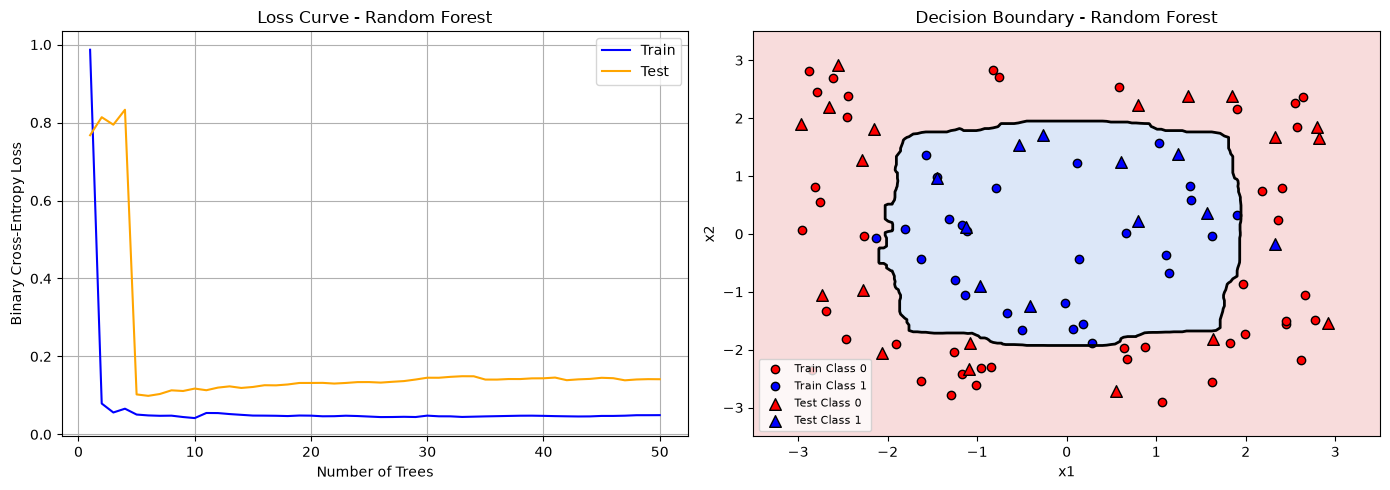

In [9]:
x1_grid, x2_grid = np.meshgrid(np.linspace(-3.5, 3.5, 150), np.linspace(-3.5, 3.5, 150))
grid_poly = poly.transform(np.c_[x1_grid.ravel(), x2_grid.ravel()])
grid_probabilities = predict_probability(trees, grid_poly).reshape(x1_grid.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, number_of_trees + 1), train_loss_history, color="blue", label="Train")
axes[0].plot(range(1, number_of_trees + 1), test_loss_history, color="orange", label="Test")
axes[0].set_title("Loss Curve - Random Forest")
axes[0].set_xlabel("Number of Trees")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].contourf(x1_grid, x2_grid, grid_probabilities, levels=[0, 0.5, 1], colors=["#f4c6c6", "#c6d8f4"], alpha=0.6)
axes[1].contour(x1_grid, x2_grid, grid_probabilities, levels=[0.5], colors="black", linewidths=2)
axes[1].scatter(X_train_original[y_train == 0, 0], X_train_original[y_train == 0, 1], color="red", edgecolor="black", label="Train Class 0")
axes[1].scatter(X_train_original[y_train == 1, 0], X_train_original[y_train == 1, 1], color="blue", edgecolor="black", label="Train Class 1")
axes[1].scatter(X_test_original[y_test == 0, 0], X_test_original[y_test == 0, 1], color="red", marker="^", s=70, edgecolor="black", label="Test Class 0")
axes[1].scatter(X_test_original[y_test == 1, 0], X_test_original[y_test == 1, 1], color="blue", marker="^", s=70, edgecolor="black", label="Test Class 1")
axes[1].set_title("Decision Boundary - Random Forest")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Comparison with Scikit-Learn

In [10]:
sklearn_forest = RandomForestClassifier(n_estimators=number_of_trees, max_depth=max_depth, max_features=max_features, random_state=42)
sklearn_forest.fit(X_train, y_train)
sklearn_test_metrics = evaluate(y_test, sklearn_forest.predict_proba(X_test)[:, 1])

print(f"{'Metric':<12}{'From Scratch':>14}{'Sklearn':>10}")
print("-" * 36)
for name, scratch_value, sklearn_value in zip(["Loss", "Accuracy", "Precision", "Recall", "F1 Score"], test_metrics, sklearn_test_metrics):
    print(f"{name:<12}{scratch_value:>14.4f}{sklearn_value:>10.4f}")

Metric        From Scratch   Sklearn
------------------------------------
Loss                0.1415    0.1228
Accuracy            0.9667    0.9667
Precision           1.0000    1.0000
Recall              0.9091    0.9091
F1 Score            0.9524    0.9524
